# One Soil Test
**Can weather readings tell a crop classifier which single soil variable to request?**

Start with temperature, humidity and rainfall. Allow one additional measurement from nitrogen, phosphorus, potassium or pH. Compare a single measurement chosen for everyone with a measurement chosen for the weather model’s preliminary crop prediction.

### Where the question comes from

[Advancing crop recommendation with supervised learning and explainable AI](https://doi.org/10.1038/s41598-025-07003-8) compares classifiers on a complete seven-input benchmark. [Beyond accuracy in crop classification](https://doi.org/10.20935/AcadAI8570) already evaluates weather-only and nutrient-group ablations, perturbations and calibration. The narrower question here concerns **which one measurement to acquire** and whether a case-specific policy beats the best fixed choice learned from training. This is a targeted extension of the reviewed experiments, not a systematic novelty claim.

### Dataset and scope

[Atharva Ingle’s Kaggle Crop Recommendation Dataset](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset) is a balanced, augmented benchmark with 22 crop labels. This notebook uses the checksum-pinned CSV from the Fieldwise project. A soil variable counts as one abstract measurement. Lab panels, prices, soil protocols, farm IDs and yields are unavailable. The target is recovery of the recorded label, not suitability at a particular farm.

In [1]:
from pathlib import Path
from hashlib import sha256
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

source = 'https://raw.githubusercontent.com/imranali-ds/fieldwise-crop-recommendation/87bc24b1a686a013a91235cd6034831343bd3a5d/Crop_recommendation.csv'
csv = Path('Crop_recommendation.csv')
if not csv.exists():
    urlretrieve(source, csv)
assert sha256(csv.read_bytes()).hexdigest() == '54a5a6e5408668e668667efc50de2fc867c1b875e0431b4f54dd331b0a109a4e'
data = pd.read_csv(csv)
weather = ['temperature', 'humidity', 'rainfall']
tests = ['N', 'P', 'K', 'ph']
y = data['label']
assert len(data) == 2200 and y.nunique() == 22 and not data.isna().any().any()
assert not data.duplicated().any()
print(f'{len(data):,} rows; {y.nunique()} crops; {len(tests)} candidate soil measurements')

2,200 rows; 22 crops; 4 candidate soil measurements


## Evaluation design

Use five stratified outer folds. Within each outer training fold, reserve 30% as a policy-development set. Fit identical 100-tree random forests on the remaining rows for weather alone, weather plus each candidate, and all seven readings. Keep these models frozen for the outer test. Choose the best fixed test by validation accuracy. For the adaptive policy, group validation rows by the weather model’s **predicted** crop. Switch from the fixed choice only if another test correctly classifies at least two more validation rows in that group. This is a prespecified regularization rule. Ties use the listed test order. Both policies use the same fitted models and see exactly one extra reading per case.

The implementation precomputes predictions for all candidate actions to evaluate the policies offline. Routing uses weather alone. Fold outputs record each action and prediction for inspection.

In [2]:
def fit_predict(columns, train, val, test, seed):
    model = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1)
    model.fit(data.loc[train, columns], y.loc[train])
    return model.predict(data.loc[val, columns]), model.predict(data.loc[test, columns])

def run_fold(fold, outer_train, test):
    train, val = train_test_split(outer_train, test_size=0.30, stratify=y.loc[outer_train],
                                  random_state=100 + fold)
    groups, weather_pred = fit_predict(weather, train, val, test, fold)
    valid_preds, test_preds = {}, {}
    for name in tests:
        valid_preds[name], test_preds[name] = fit_predict(weather + [name], train, val, test, fold)
    correct = pd.DataFrame({k: v == y.loc[val].to_numpy() for k, v in valid_preds.items()})
    fixed = correct.sum().idxmax()
    routes = {}
    for group in np.unique(groups):
        scores = correct.loc[groups == group].sum()
        candidate = scores.idxmax()
        routes[group] = candidate if scores[candidate] >= scores[fixed] + 2 else fixed
    chosen = [routes.get(group, fixed) for group in weather_pred]
    _, full = fit_predict(weather + tests, train, val, test, fold)
    return pd.DataFrame(dict(row=test, fold=fold, label=y.loc[test].to_numpy(),
                             weather=weather_pred, fixed_test=fixed, adaptive_test=chosen,
                             fixed=test_preds[fixed], adaptive=[test_preds[t][i] for i,t in enumerate(chosen)],
                             full=full))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pred = pd.concat([run_fold(i, train, test) for i, (train, test) in enumerate(cv.split(data, y), 1)])
pred = pred.sort_values('row').reset_index(drop=True)
assert pred.row.tolist() == list(range(len(data)))
out = Path('results')
out.mkdir(exist_ok=True)
pred.to_csv(out/'predictions.csv', index=False)

In [3]:
methods = ['weather', 'fixed', 'adaptive', 'full']
summary = pd.DataFrame([dict(method=m, correct=int((pred[m] == pred.label).sum()),
                             accuracy=accuracy_score(pred.label, pred[m]),
                             macro_f1=f1_score(pred.label, pred[m], average='macro')) for m in methods])
summary.to_csv(out/'summary.csv', index=False)
folds = pred.groupby('fold').apply(lambda g: pd.Series({m: (g[m] == g.label).mean() for m in methods}))
folds.to_csv(out/'folds.csv')
print(summary.to_string(index=False))
print('Accuracy by fold:')
print(folds.round(3).to_string())
fixed_right = pred.fixed == pred.label
adaptive_right = pred.adaptive == pred.label
print('Adaptive-only correct:', sum(adaptive_right & ~fixed_right))
print('Fixed-only correct:', sum(fixed_right & ~adaptive_right))
print('Fixed measurement by fold:', pred.groupby('fold').fixed_test.first().tolist())
print('Adaptive measurements requested:', pred.adaptive_test.value_counts().to_dict())

  method  correct  accuracy  macro_f1
 weather     2006  0.911818  0.911069
   fixed     2144  0.974545  0.974421
adaptive     2161  0.982273  0.982175
    full     2188  0.994545  0.994544
Accuracy by fold:
      weather  fixed  adaptive   full
fold                                 
1       0.909  0.982     0.986  0.993
2       0.900  0.966     0.975  0.995
3       0.914  0.977     0.982  0.998
4       0.914  0.977     0.980  0.995
5       0.923  0.970     0.989  0.991
Adaptive-only correct: 18
Fixed-only correct: 1
Fixed measurement by fold: ['P', 'P', 'K', 'K', 'K']
Adaptive measurements requested: {'K': 1212, 'P': 890, 'N': 78, 'ph': 20}


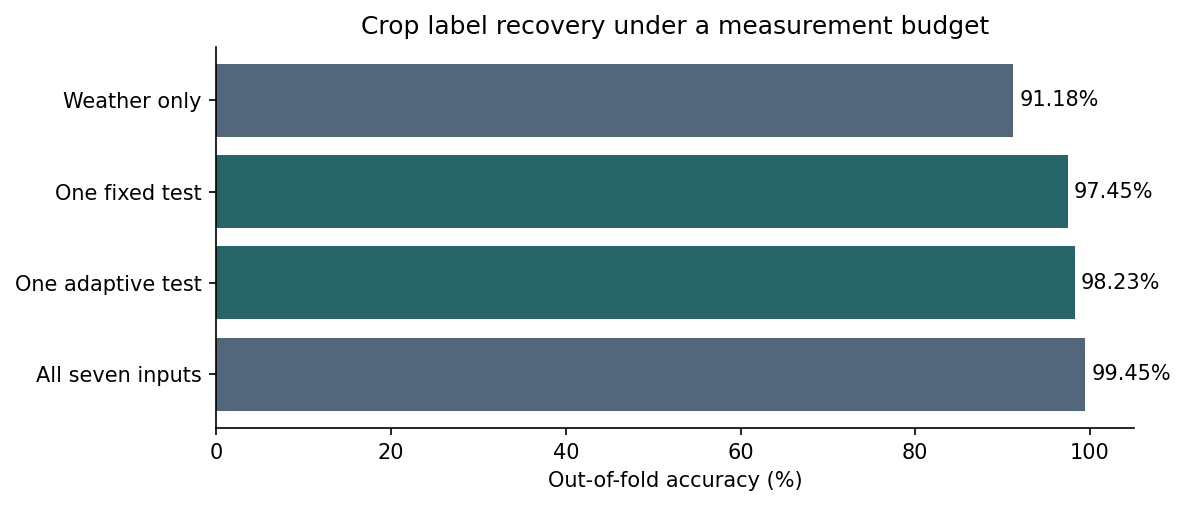

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ['#52677b', '#286569', '#286569', '#52677b']
bars = ax.barh(['Weather only', 'One fixed test', 'One adaptive test', 'All seven inputs'],
               100 * summary.accuracy, color=colors)
ax.set(xlim=(0, 105), xlabel='Out-of-fold accuracy (%)', title='Crop label recovery under a measurement budget')
ax.invert_yaxis()
ax.bar_label(bars, fmt='%.2f%%', padding=3)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(out/'comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Interpreting the comparison

Read the adaptive-only and fixed-only correct counts together. Their difference is the net number of labels recovered by switching policies across the same held-out rows. The all-input model is a reference with a larger measurement budget. The folds share training observations, and a single stratified partition does not measure between-farm or between-season uncertainty. A next study would repeat this comparison on a farm-identified dataset with measured collection costs and a geographic holdout.

**Observed result:** The adaptive policy recovered 2,161 of 2,200 labels, compared with 2,144 for the fixed policy. It corrected 18 fixed-policy errors and introduced one additional error. The fixed policy selected P in two folds and K in three. The applied result is a 0.77 percentage-point gain on this benchmark under the equal-cost assumption.